In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df=pd.read_csv("OECD.ENV.EPI,DSD_EWASTE@DF_EWASTE,,complete,2026-10-29 13-20-54.csv")

In [9]:
df.head(5)

,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,ACTION,REF_AREA,Reference area,FREQ,Frequency of observation,PRODUCT_CATEGORIES,Product categories,...,TIME_PERIOD,Time period,OBS_VALUE,Observation value,OBS_STATUS,Observation status,UNIT_MULT,Unit multiplier,DECIMALS,Decimals
0,DATAFLOW,OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0),Waste - Electrical and electronic equipment (e...,I,AUS,Australia,A,Annual,EE6,Total,...,2000,NaN,16.25509,NaN,A,Normal value,0,Units,2,Two
1,DATAFLOW,OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0),Waste - Electrical and electronic equipment (e...,I,AUS,Australia,A,Annual,EE6,Total,...,2005,NaN,24.44847,NaN,A,Normal value,0,Units,2,Two
2,DATAFLOW,OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0),Waste - Electrical and electronic equipment (e...,I,AUS,Australia,A,Annual,EE6,Total,...,2010,NaN,30.98496,NaN,A,Normal value,0,Units,2,Two
3,DATAFLOW,OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0),Waste - Electrical and electronic equipment (e...,I,AUS,Australia,A,Annual,EE6,Total,...,2011,NaN,32.31625,NaN,A,Normal value,0,Units,2,Two
4,DATAFLOW,OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0),Waste - Electrical and electronic equipment (e...,I,AUS,Australia,A,Annual,EE6,Total,...,2012,NaN,31.90771,NaN,A,Normal value,0,Units,2,Two


In [10]:
df.shape

(14589, 24)

In [11]:
df.columns

Index(['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'ACTION', 'REF_AREA',
       'Reference area', 'FREQ', 'Frequency of observation',
       'PRODUCT_CATEGORIES', 'Product categories', 'UNIT_MEASURE',
       'Unit of measure', 'MEASURE', 'Measure', 'TIME_PERIOD', 'Time period',
       'OBS_VALUE', 'Observation value', 'OBS_STATUS', 'Observation status',
       'UNIT_MULT', 'Unit multiplier', 'DECIMALS', 'Decimals'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14589 entries, 0 to 14588
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   STRUCTURE                 14589 non-null  str    
 1   STRUCTURE_ID              14589 non-null  str    
 2   STRUCTURE_NAME            14589 non-null  str    
 3   ACTION                    14589 non-null  str    
 4   REF_AREA                  14589 non-null  str    
 5   Reference area            14589 non-null  str    
 6   FREQ                      14589 non-null  str    
 7   Frequency of observation  14589 non-null  str    
 8   PRODUCT_CATEGORIES        14589 non-null  str    
 9   Product categories        14589 non-null  str    
 10  UNIT_MEASURE              14589 non-null  str    
 11  Unit of measure           14589 non-null  str    
 12  MEASURE                   14589 non-null  str    
 13  Measure                   14589 non-null  str    
 14  TIME_PERIOD      

In [12]:
df.describe()

,TIME_PERIOD,Time period,OBS_VALUE,Observation value,UNIT_MULT,DECIMALS
count,14589.000000,0.0,14589.000000,0.0,14589.000000,14589.0
mean,2018.485297,NaN,91.769969,NaN,1.500720,2.0
std,4.561872,NaN,497.970981,NaN,1.500051,0.0
min,2000.000000,NaN,0.000000,NaN,0.000000,2.0
25%,2017.000000,NaN,1.315809,NaN,0.000000,2.0
50%,2020.000000,NaN,5.732679,NaN,3.000000,2.0
75%,2022.000000,NaN,27.464000,NaN,3.000000,2.0
max,2024.000000,NaN,14502.130000,NaN,3.000000,2.0


In [13]:
waste_df = df[
    (df["Measure"] == "Total waste generated") &
    (df["Product categories"] == "Total") &
    (df["Unit of measure"] == "Tonnes")
].copy()

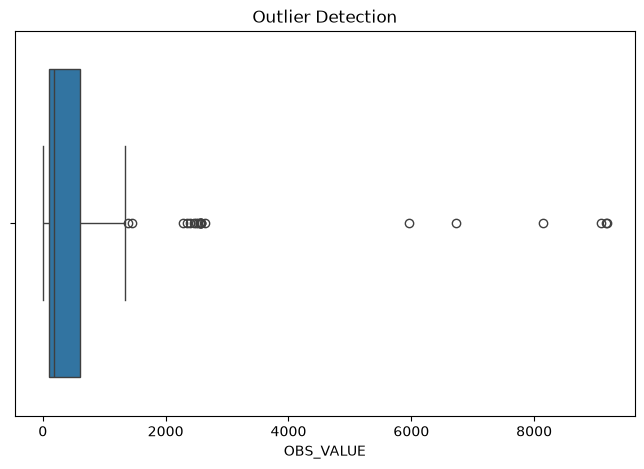

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=waste_df["OBS_VALUE"])

plt.title("Outlier Detection")
plt.show()

In [15]:
Q1 = waste_df["OBS_VALUE"].quantile(0.25)

Q3 = waste_df["OBS_VALUE"].quantile(0.75)

print("Q1:", Q1)
print("Q3:", Q3)

Q1: 94.53999999999999
Q3: 606.5825


In [16]:
IQR = Q3 - Q1

print("IQR:", IQR)
lower_limit = Q1 - (1.5 * IQR)

upper_limit = Q3 + (1.5 * IQR)

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

IQR: 512.0425
Lower Limit: -673.5237500000001
Upper Limit: 1374.64625


In [17]:
outliers = waste_df[
    (waste_df["OBS_VALUE"] < lower_limit) |
    (waste_df["OBS_VALUE"] > upper_limit)
]

print(outliers)

     STRUCTURE                            STRUCTURE_ID  \
2773  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2774  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2775  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2776  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2777  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2778  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2779  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2780  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2781  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2782  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2783  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2784  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2785  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2819  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2820  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2863  DATAFLOW  OECD.ENV.EPI:DSD_EWASTE@DF_EWASTE(1.0)   
2864  DATAFLOW

In [18]:
print("Number of potential outliers:", len(outliers))

Number of potential outliers: 21


In [19]:
print(outliers[[
    "Reference area",
    "TIME_PERIOD",
    "OBS_VALUE"
]])

     Reference area  TIME_PERIOD    OBS_VALUE
2773          Japan         2010  2285.310552
2774          Japan         2011  2341.664828
2775          Japan         2012  2399.801195
2776          Japan         2013  2453.860138
2777          Japan         2014  2498.411403
2778          Japan         2015  2532.065331
2779          Japan         2016  2552.002507
2780          Japan         2017  2560.100284
2781          Japan         2018  2564.149181
2782          Japan         2019  2568.959087
2783          Japan         2020  2573.910361
2784          Japan         2021  2579.000000
2785          Japan         2022  2638.100000
2819         Mexico         2020  1394.742770
2820         Mexico         2021  1448.391064
2863  United States         2000  5969.275589
2864  United States         2005  6731.310771
2865  United States         2010  8137.447118
2866  United States         2015  9080.919247
2867  United States         2017  9180.709569
2868  United States         2018  

In [20]:
print(outliers[[
    "Reference area",
    "TIME_PERIOD",
    "Measure",
    "Product categories",
    "Unit of measure",
    "OBS_VALUE"
]])

     Reference area  TIME_PERIOD                Measure Product categories  \
2773          Japan         2010  Total waste generated              Total   
2774          Japan         2011  Total waste generated              Total   
2775          Japan         2012  Total waste generated              Total   
2776          Japan         2013  Total waste generated              Total   
2777          Japan         2014  Total waste generated              Total   
2778          Japan         2015  Total waste generated              Total   
2779          Japan         2016  Total waste generated              Total   
2780          Japan         2017  Total waste generated              Total   
2781          Japan         2018  Total waste generated              Total   
2782          Japan         2019  Total waste generated              Total   
2783          Japan         2020  Total waste generated              Total   
2784          Japan         2021  Total waste generated         

In [17]:
df.isnull().sum()

STRUCTURE                       0
STRUCTURE_ID                    0
STRUCTURE_NAME                  0
ACTION                          0
REF_AREA                        0
Reference area                  0
FREQ                            0
Frequency of observation        0
PRODUCT_CATEGORIES              0
Product categories              0
UNIT_MEASURE                    0
Unit of measure                 0
MEASURE                         0
Measure                         0
TIME_PERIOD                     0
Time period                 14589
OBS_VALUE                       0
Observation value           14589
OBS_STATUS                      0
Observation status              0
UNIT_MULT                       0
Unit multiplier                 0
DECIMALS                        0
Decimals                        0
dtype: int64

In [21]:
df.isnull().sum().sum()

np.int64(29178)

In [22]:
df = df.drop(columns=["Time period", "Observation value"])

In [23]:
df.isnull().sum()

STRUCTURE                   0
STRUCTURE_ID                0
STRUCTURE_NAME              0
ACTION                      0
REF_AREA                    0
Reference area              0
FREQ                        0
Frequency of observation    0
PRODUCT_CATEGORIES          0
Product categories          0
UNIT_MEASURE                0
Unit of measure             0
MEASURE                     0
Measure                     0
TIME_PERIOD                 0
OBS_VALUE                   0
OBS_STATUS                  0
Observation status          0
UNIT_MULT                   0
Unit multiplier             0
DECIMALS                    0
Decimals                    0
dtype: int64

In [24]:
df.duplicated().sum()

np.int64(0)

In [28]:
df.dtypes

STRUCTURE                       str
STRUCTURE_ID                    str
STRUCTURE_NAME                  str
ACTION                          str
REF_AREA                        str
Reference area                  str
FREQ                            str
Frequency of observation        str
PRODUCT_CATEGORIES              str
Product categories              str
UNIT_MEASURE                    str
Unit of measure                 str
MEASURE                         str
Measure                         str
TIME_PERIOD                   int64
OBS_VALUE                   float64
OBS_STATUS                      str
Observation status              str
UNIT_MULT                     int64
Unit multiplier                 str
DECIMALS                      int64
Decimals                        str
dtype: object

In [29]:
df.describe()

,TIME_PERIOD,OBS_VALUE,UNIT_MULT,DECIMALS
count,14589.000000,14589.000000,14589.000000,14589.0
mean,2018.485297,91.769969,1.500720,2.0
std,4.561872,497.970981,1.500051,0.0
min,2000.000000,0.000000,0.000000,2.0
25%,2017.000000,1.315809,0.000000,2.0
50%,2020.000000,5.732679,3.000000,2.0
75%,2022.000000,27.464000,3.000000,2.0
max,2024.000000,14502.130000,3.000000,2.0


In [34]:
df["Measure"].value_counts()

Measure
Products put on the market    4254
Waste collected               4056
Total waste generated         3190
Recycling                     3082
Reused and remanufactured        7
Name: count, dtype: int64

In [35]:
df["Product categories"].value_counts()

Product categories
Total                                            3343
Large equipment                                  1711
Small equipment                                  1631
Temperature exchange equipment                   1627
Small IT and telecommunication equipment         1595
Screens and monitors                             1593
Lamps                                            1561
Large equipment excluding photovoltaic panels     814
Photovoltaic panels                               714
Name: count, dtype: int64

In [47]:
df["Unit of measure"].value_counts()

Unit of measure
Tonnes                    7298
Kilogrammes per person    7291
Name: count, dtype: int64

In [37]:
df.columns

Index(['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'ACTION', 'REF_AREA',
       'Reference area', 'FREQ', 'Frequency of observation',
       'PRODUCT_CATEGORIES', 'Product categories', 'UNIT_MEASURE',
       'Unit of measure', 'MEASURE', 'Measure', 'TIME_PERIOD', 'OBS_VALUE',
       'OBS_STATUS', 'Observation status', 'UNIT_MULT', 'Unit multiplier',
       'DECIMALS', 'Decimals'],
      dtype='str')

In [38]:
df.select_dtypes(include="object").columns

C:\Users\HP\AppData\Local\Temp\ipykernel_5712\1196084386.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object").columns


Index(['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'ACTION', 'REF_AREA',
       'Reference area', 'FREQ', 'Frequency of observation',
       'PRODUCT_CATEGORIES', 'Product categories', 'UNIT_MEASURE',
       'Unit of measure', 'MEASURE', 'Measure', 'OBS_STATUS',
       'Observation status', 'Unit multiplier', 'Decimals'],
      dtype='str')

In [48]:
df["Reference area"].nunique()

47

In [49]:
df["Reference area"].value_counts().head(10)

Reference area
Switzerland    788
Costa Rica     595
Japan          438
Australia      420
Israel         420
Hungary        418
Luxembourg     414
Poland         400
Cyprus         392
Finland        380
Name: count, dtype: int64

In [50]:
from sklearn.preprocessing import OneHotEncoder

In [58]:

encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")

country_encoded = encoder.fit_transform(df[["Reference area"]])


In [59]:
encoded_df = pd.DataFrame(
    country_encoded,
    columns=encoder.get_feature_names_out(["Reference area"]),
    index=df.index
)

In [60]:
encoded_df.head()

,Reference area_Australia,Reference area_Austria,Reference area_Bangladesh,Reference area_Belgium,Reference area_Bosnia and Herzegovina,Reference area_Bulgaria,Reference area_Canada,Reference area_Chile,Reference area_Colombia,Reference area_Costa Rica,...,Reference area_Poland,Reference area_Portugal,Reference area_Romania,Reference area_Slovak Republic,Reference area_Slovenia,Reference area_Spain,Reference area_Sweden,Reference area_Switzerland,Reference area_Ukraine,Reference area_United States
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [61]:
waste_df = df[
    (df["Measure"] == "Total waste generated") &
    (df["Product categories"] == "Total") &
    (df["Unit of measure"] == "Tonnes")
].copy()

In [62]:
X = waste_df[["TIME_PERIOD", "Reference area"]]

y = waste_df["OBS_VALUE"]

In [63]:
waste_df = waste_df.sort_values("TIME_PERIOD")

split_index = int(len(waste_df) * 0.8)

X_train = X.loc[waste_df.index[:split_index]]
X_test = X.loc[waste_df.index[split_index:]]

y_train = y.loc[waste_df.index[:split_index]]
y_test = y.loc[waste_df.index[split_index:]]

In [64]:
from sklearn.preprocessing import StandardScaler

In [65]:
scaler = StandardScaler()

In [66]:
X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

ValueError: could not convert string to float: 'Australia'

In [67]:
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

NameError: name 'X_train_scaled' is not defined

In [68]:
print("X shape:", X.shape)
print("X columns:")
print(X.columns.tolist())

X shape: (236, 2)
X columns:
['TIME_PERIOD', 'Reference area']


In [69]:
X = pd.get_dummies(X, columns=["Reference area"], dtype=int)

In [70]:
print("X shape:", X.shape)
print(X.head())

X shape: (236, 28)
      TIME_PERIOD  Reference area_Australia  Reference area_Bangladesh  \
2668         2000                         1                          0   
2669         2005                         1                          0   
2670         2010                         1                          0   
2671         2011                         1                          0   
2672         2012                         1                          0   

      Reference area_Bosnia and Herzegovina  Reference area_Canada  \
2668                                      0                      0   
2669                                      0                      0   
2670                                      0                      0   
2671                                      0                      0   
2672                                      0                      0   

      Reference area_Chile  Reference area_Colombia  \
2668                     0                        0   
2669 

In [71]:
waste_df = waste_df.sort_values("TIME_PERIOD")

split_index = int(len(waste_df) * 0.8)

X_train = X.loc[waste_df.index[:split_index]]
X_test = X.loc[waste_df.index[split_index:]]

y_train = y.loc[waste_df.index[:split_index]]
y_test = y.loc[waste_df.index[split_index:]]

In [72]:
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training rows: 188
Testing rows: 48
Training shape: (188, 28)
Testing shape: (48, 28)


In [73]:
from sklearn.preprocessing import StandardScaler

In [74]:
scaler = StandardScaler()

In [75]:
X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [76]:
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (188, 28)
Testing shape: (48, 28)


In [77]:
len(X_test)

48

In [78]:
len(y_test)

48

In [79]:
from sklearn.linear_model import LinearRegression

In [80]:
model = LinearRegression()

In [81]:
model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](28,)","[ 156.24, -66.75, -67.36,...,-126.06,-149.22,1315.87]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,678
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,28
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,25
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](28,)","[16.53,14.25,14.25,..., 0. , 0. , 0. ]"


In [82]:
y_pred = model.predict(X_test_scaled)

In [84]:
comparison = pd.DataFrame({
    "Actual E-Waste": y_test.values,
    "Predicted E-Waste": y_pred
})

comparison.head(10)#test prediction

,Actual E-Waste,Predicted E-Waste
0,142.800,344.767368
1,2579.000,2668.202677
2,171.820,213.648968
3,676.267,870.188888
4,545.569,646.539824
5,230.000,360.231360
6,774.430,883.310677
7,165.400,375.373347
8,15.027,76.057624
9,203.850,420.614249


In [85]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)
print(f"MAE={mae:5.2f} MSE={mse:5.2f} RMSE={rmse:5.2f} R**2={r2:.3f}")

MAE=130.34 MSE=29714.38 RMSE=172.38 R**2=0.910
